<a href="https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/solutions/Session06_exploratory_data_analysis_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۶: تحلیل اکتشافی داده (EDA)، یک مطالعهٔ موردی کامل

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session06_exploratory_data_analysis.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

کتابخانه‌ها و داده‌هایی که پاسخ‌ها به آن‌ها نیاز دارند:

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Data_Science_Course/main/data/"
df = pd.read_csv(DATA_URL + "diamonds.csv").drop_duplicates()
df = df[~((df[["x", "y", "z"]] == 0).any(axis=1) | (df["y"] > 20) | (df["z"] > 20))]
COLOR = ["J", "I", "H", "G", "F", "E", "D"]
df["color"] = pd.Categorical(df["color"], categories=COLOR, ordered=True)
tips = pd.read_csv(DATA_URL + "tips.csv")

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

معمای «رنگ» را حل کنید: نشان دهید که با ثابت نگه داشتن وزن (مثلاً ۰٫۹ تا ۱٫۱ قیراط)، رنگ D گران‌تر از J است.

</div>

In [2]:
one_carat = df[df["carat"].between(0.9, 1.1)]
pd.DataFrame({
    "all diamonds": df.groupby("color", observed=True)["price"].median(),
    "0.9-1.1 carat": one_carat.groupby("color", observed=True)["price"].median(),
})

,all diamonds,0.9-1.1 carat
color,,
J,4234.5,3599.0
I,3720.0,3968.0
H,3447.0,4513.0
G,2242.0,5241.0
F,2345.0,4924.0
E,1740.0,4921.0
D,1842.0,5079.5


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

یک ستون `volume = x * y * z` بسازید و رابطهٔ آن را با `carat` رسم کنید. آیا دادهٔ مشکوکی می‌بینید؟

</div>

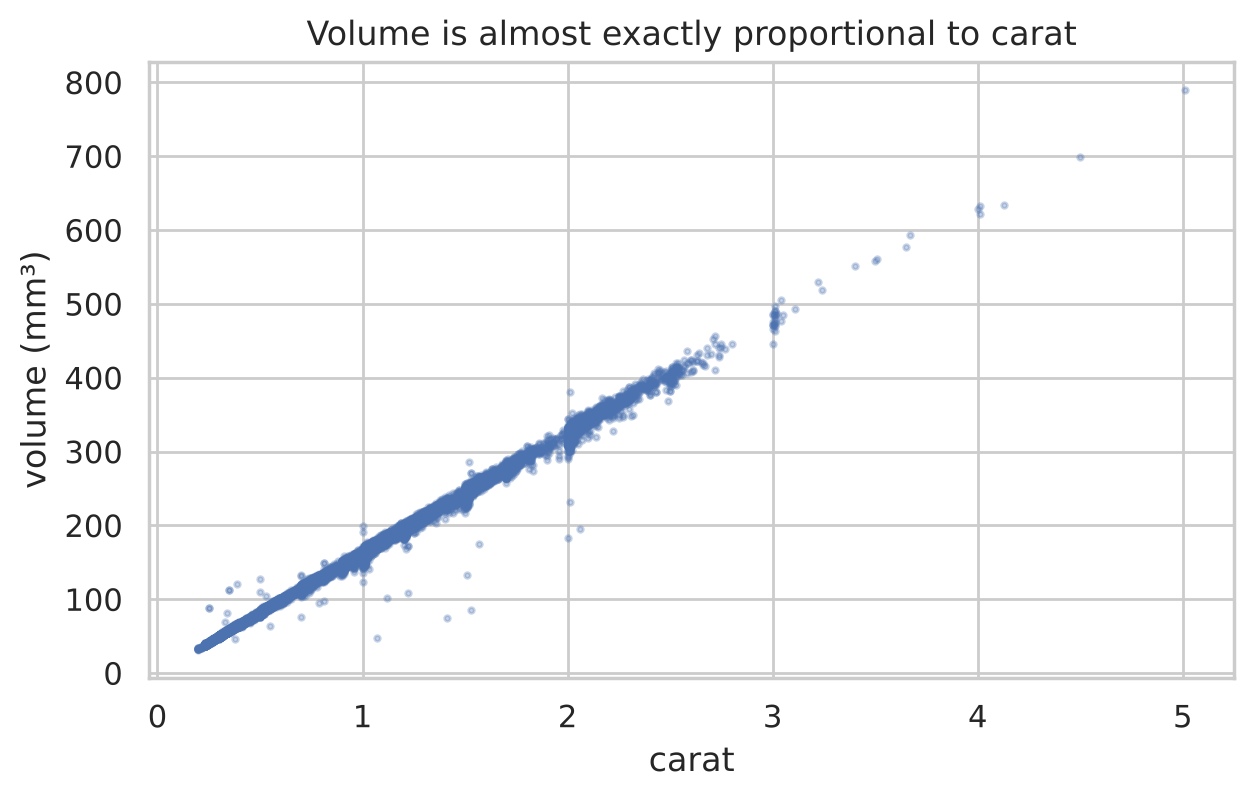

count    53772.0
mean       163.3
std          3.8
min         44.2
25%        161.6
50%        163.5
75%        165.3
max        351.2
dtype: float64


In [3]:
df["volume"] = df["x"] * df["y"] * df["z"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df["carat"], df["volume"], s=4, alpha=0.3)
ax.set_xlabel("carat")
ax.set_ylabel("volume (mm³)")
ax.set_title("Volume is almost exactly proportional to carat")
plt.show()

ratio = df["volume"] / df["carat"]
print(ratio.describe().round(1))

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

نسبت حجم به قیراط تقریباً ثابت است (حدود ۱۶۳ میلی‌متر مکعب به ازای هر قیراط). نقاطی که از خط دور افتاده‌اند احتمالاً خطای اندازه‌گیری یکی از ابعادند و ارزش بررسی دارند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

با `sns.displot(..., col="cut")` توزیع `log10(price)` را برای هر گروه تراش رسم کنید.

</div>

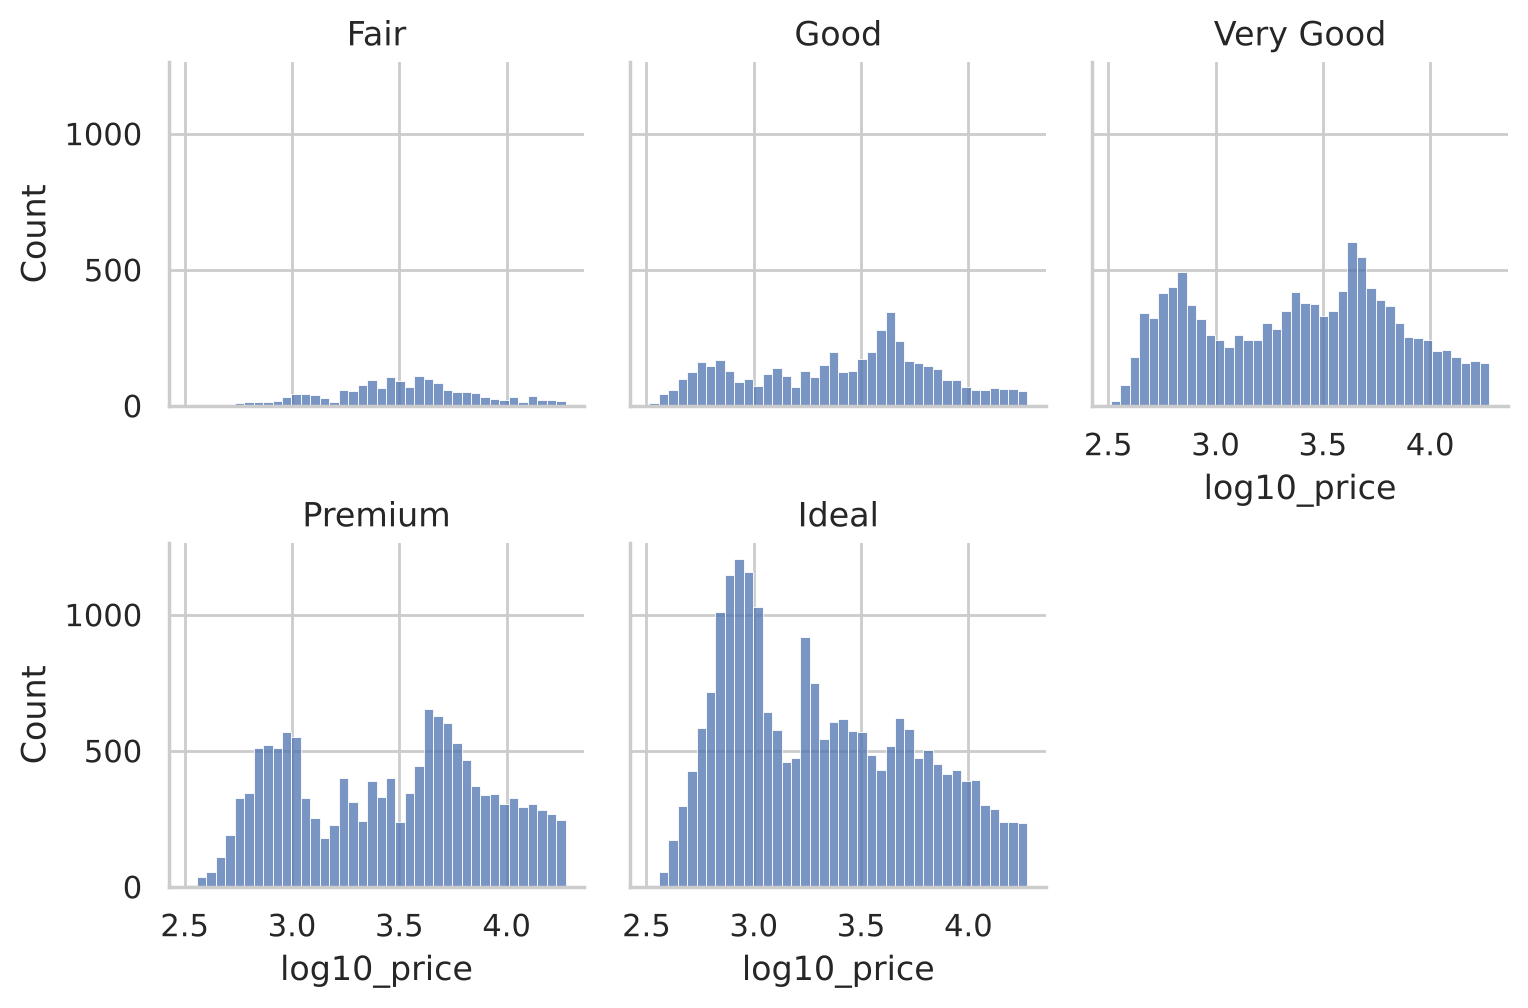

In [4]:
CUT = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
g = sns.displot(df.assign(log10_price=np.log10(df["price"])), x="log10_price",
                col="cut", col_order=CUT, col_wrap=3, height=2.6, bins=40)
g.set_titles("{col_name}")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

اختلاف قیمت میانهٔ الماس‌های ۰٫۹۵ تا ۰٫۹۹ قیراط و ۱٫۰۰ تا ۱٫۰۴ قیراط چقدر است؟ این اختلاف چه چیزی دربارهٔ بازار می‌گوید؟

</div>

In [5]:
below = df[df["carat"].between(0.95, 0.99)]["price"]
above = df[df["carat"].between(1.00, 1.04)]["price"]
print(f"0.95-0.99 carat: n={len(below):5d}, median price = {below.median():,.0f}")
print(f"1.00-1.04 carat: n={len(above):5d}, median price = {above.median():,.0f}")
print(f"jump: {above.median() / below.median() - 1:.0%}")

0.95-0.99 carat: n=  281, median price = 3,918
1.00-1.04 carat: n= 5663, median price = 5,041
jump: 29%


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

فقط چند صدم قیراط اختلاف، اما قیمت میانه به‌طور محسوس بالا می‌رود و تعداد الماس‌های بالای ۱ قیراط هم خیلی بیشتر است. بازار برای برچسب «۱ قیراط» ارزش جداگانه‌ای قائل است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۵

یک EDA کوتاه روی دادهٔ `tips` انجام دهید و سه یافتهٔ اصلی را به زبان ساده بنویسید.

</div>

      count  median
day                
Fri      19    15.4
Sat      87    18.2
Sun      76    19.6
Thur     62    16.2 

size
1    20.3
2    15.6
3    15.9
4    14.7
5    12.1
6    16.3
Name: tip_pct, dtype: float64 

corr(total_bill, tip_pct): -0.34


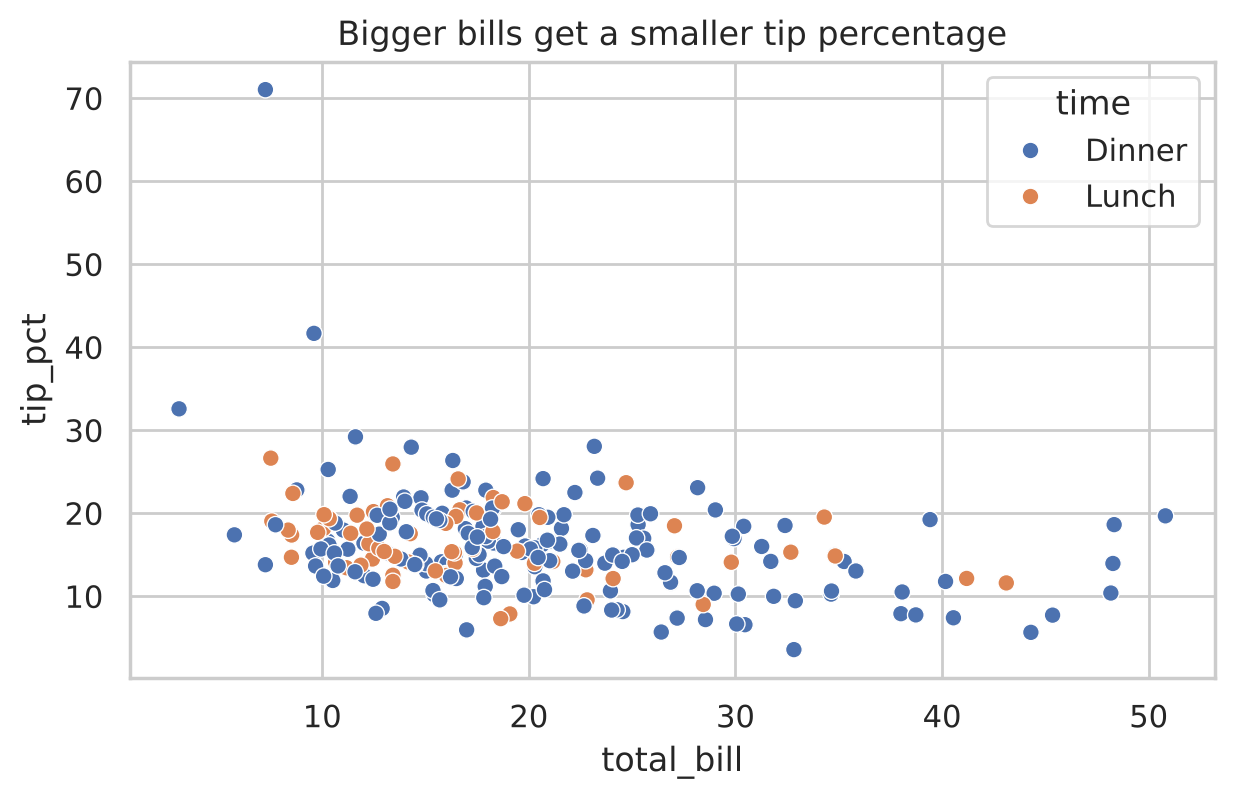

In [6]:
tips["tip_pct"] = tips["tip"] / tips["total_bill"] * 100
print(tips.groupby("day")["total_bill"].agg(["count", "median"]).round(1), "\n")
print(tips.groupby("size")["tip_pct"].median().round(1), "\n")
print("corr(total_bill, tip_pct):", tips["total_bill"].corr(tips["tip_pct"]).round(2))

fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=tips, x="total_bill", y="tip_pct", hue="time", ax=ax)
ax.set_title("Bigger bills get a smaller tip percentage")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

سه یافتهٔ نمونه:

1. بیشتر مشتری‌ها آخر هفته (شنبه و یکشنبه) می‌آیند و صورت‌حساب‌های آخر هفته کمی بزرگ‌ترند.
2. درصد انعام با بزرگ شدن صورت‌حساب **کم** می‌شود (همبستگی منفی)، هرچند مبلغ انعام زیاد می‌شود.
3. برای میزهای ۲ تا ۴ نفره، که بیشتر داده را تشکیل می‌دهند، میانهٔ درصد انعام تقریباً ثابت و حدود ۱۵ تا ۱۶ درصد است.

</div>